# Multi-Agent Intersection Coordination Lab

**Goal.** Study a *tragedy of the commons* among autonomous vehicles at an unsignalised intersection, and automate the research loop with an agent team.

Two layers of agents:

1. **Vehicle agents (simulation).** Each vehicle is either a **cooperator**, which follows the intersection manager's protocol, or a **defector**, which acts selfishly and enters whenever the box *looks* clear to it. Cooperators are served by one of two coordination protocols:
   * **FCFS reservation:** the oldest waiting cooperator's axis (north–south or east–west) is granted the box.
   * **Auction:** each waiting cooperator bids its value of time × waiting time, and the axis with the highest total bid wins.

   When vehicles from conflicting axes enter together, a **conflict** blocks the intersection for a clearance period. Shared road capacity is the commons.
2. **Research agents (LangGraph).** For each research question:
   * A **hypothesis agent** (LLM) states a hypothesis, picks an experiment from a registry and predicts the direction of the effect.
   * A **methodologist** (embedding similarity) checks that the chosen experiment actually addresses the question, and overrides clear mismatches.
   * The **simulator** runs the experiment over many random seeds.
   * The **statistician** computes means and bootstrap 95% confidence intervals (deterministic).
   * The **analyst** (LLM) writes the finding.
   * The **claim critic** (deterministic) rejects findings that use numbers not produced by the statistician, or whose verdict contradicts the confidence interval, and sends them back for revision.

This is an original simulation written for this portfolio. It is *inspired by* the theme of cooperation and shared-resource dilemmas among autonomous agents, and is not a reproduction of any published model.

**Data.** Fully synthetic: generated by the simulator, with fixed seeds for reproducibility.

## 1. Setup

In [1]:
import os
os.environ["TQDM_DISABLE"] = "1"   # keep notebook output readable
import time, json, re, warnings
from collections import deque
from functools import lru_cache
from pathlib import Path
from typing import Literal, Optional, TypedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import plotly.graph_objects as go
from pydantic import BaseModel
from langgraph.graph import StateGraph, END
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### LLM provider (shared `agentkit` package)

All agents call language models through `agentkit` (in `Agentic AI/agentkit/`), a provider-independent layer. **No code changes are needed to switch providers**: put keys in a `.env` file (see `.env.example`) and re-run.

| Configuration found | Provider used |
|---|---|
| `OPENAI_API_KEY` | OpenAI (`gpt-4.1-mini` by default, or `OPENAI_MODEL`; `OPENAI_BASE_URL` for any OpenAI-compatible server) |
| `GOOGLE_API_KEY` or `GEMINI_API_KEY` | Google Gemini (`gemini-3.1-flash-lite` by default, or `GEMINI_MODEL`) |
| an Ollama server with a model pulled | Ollama (best installed model, or `OLLAMA_MODEL`) |
| nothing (offline default) | a local Hugging Face model: the best Apache-2.0 Qwen3 model that fits in free memory (8B / 4B / 1.7B / 0.6B) |

`LLM_PROVIDER` forces a choice. Outputs are validated against Pydantic schemas, using native JSON mode where the provider supports it, and tools use each provider's native tool calling. Transient errors are retried with backoff, and an API failure falls back to the local model; the fallback is logged and labelled. **Caching is off by default, so every response below was generated live in this run.** With `LLM_CACHE=readwrite` or `replay`, every cached response is flagged as `[CACHE REPLAY]` and counted separately. Each call is recorded in `outputs/llm_calls.jsonl`, and the last cell prints a provenance report.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent))      # Agentic AI/, which holds the shared agentkit package
from agentkit import LLM, configure_logging
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
log = configure_logging(OUT)

In [3]:
llm = LLM()
print(llm.describe())

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Provider: huggingface   Model: Qwen/Qwen3-1.7B
Why: no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory
API keys: OpenAI not set, Gemini not set | cache: off (every call is live) | fallback to local: on
.env files loaded: none


## 2. The simulator

* One time step is one second, and each run lasts one hour. On each of the four approaches, a vehicle arrives with probability `LAM` per second. Only the vehicle at the head of a queue can act.
* North–south vehicles are mutually compatible, as are east–west vehicles; the two axes conflict. A crossing takes `CROSS` seconds.
* **Defectors** enter when they see no conflicting vehicle *inside* the box. They cannot see what the manager is about to grant, and with probability `P_ERR` they misjudge a gap. They make their decision in the same second as the manager, so they can collide with vehicles that hold a legitimate grant.
* A **conflict** blocks the whole intersection for `PENALTY` seconds, which models emergency braking and clearance.
* Delay is measured from arrival to entering the box, for vehicles arriving after a two-minute warm-up. Vehicles still queued at the end of the hour count against **completion**.

In [4]:
APPROACHES = ["N", "E", "S", "W"]
AXIS = {"N": 0, "S": 0, "E": 1, "W": 1}
LAM, CROSS, PENALTY, P_ERR, HORIZON, WARMUP = 0.09, 2, 8, 0.10, 3600, 120

def simulate(participation: float, protocol: str, seed: int, record: bool = False) -> dict:
    rng = np.random.default_rng(seed)
    queues = {a: deque() for a in APPROACHES}
    zone, blocked_until, conflicts, n_arrived = [], -1, 0, 0
    done, qlen = [], []
    for t in range(HORIZON):
        for a in APPROACHES:
            if rng.random() < LAM:
                # [arrival time, is cooperator, value of time]
                queues[a].append((t, rng.random() < participation, float(rng.lognormal(0, 0.5))))
                n_arrived += 1
        zone = [z for z in zone if z[1] > t]
        if record:
            qlen.append(sum(len(q) for q in queues.values()))
        if t < blocked_until:
            continue
        busy = {ax for ax, _ in zone}
        heads = {a: q[0] for a, q in queues.items() if q}
        entrants = []
        for a, v in heads.items():                       # selfish agents decide on what they can see
            if not v[1] and ((1 - AXIS[a]) not in busy or rng.random() < P_ERR):
                entrants.append(a)
        coop = {a: v for a, v in heads.items() if v[1]}
        if coop:                                         # the manager serves cooperators
            if protocol == "fcfs":
                axis = AXIS[min(coop, key=lambda a: coop[a][0])]
            elif protocol == "auction":
                bids = [0.0, 0.0]
                for a, v in coop.items():
                    bids[AXIS[a]] += v[2] * (t - v[0] + 1)
                axis = int(np.argmax(bids))
            else:
                raise ValueError(protocol)
            if (1 - axis) not in busy:
                entrants += [a for a in coop if AXIS[a] == axis]
        if not entrants:
            continue
        if len(busy | {AXIS[a] for a in entrants}) == 2:
            conflicts += 1
            blocked_until = t + PENALTY
            finish = t + PENALTY + CROSS
            zone = [(ax, max(f, finish)) for ax, f in zone]
        else:
            finish = t + CROSS
        for a in entrants:
            arr, is_coop, val = queues[a].popleft()
            zone.append((AXIS[a], finish))
            done.append((arr, t - arr, is_coop, val))
    d = pd.DataFrame(done, columns=["arrival", "delay", "coop", "value"])
    d = d[d.arrival >= WARMUP]
    out = {"participation": participation, "protocol": protocol, "seed": seed,
           "mean_delay": d.delay.mean(), "p95_delay": d.delay.quantile(0.95),
           "value_weighted_delay": (d.delay * d.value).sum() / d.value.sum(),
           "coop_delay": d[d.coop].delay.mean() if d.coop.any() else np.nan,
           "defector_delay": d[~d.coop].delay.mean() if (~d.coop).any() else np.nan,
           "throughput_per_min": len(done) / (HORIZON / 60), "completion": len(done) / max(1, n_arrived),
           "conflicts_per_hour": conflicts * 3600 / HORIZON}
    if record:
        out["queue_length"] = qlen
    return out

t0 = time.time(); r = simulate(1.0, "fcfs", 0); print(f"one run: {time.time() - t0:.2f}s")
{k: round(v, 3) if isinstance(v, float) else v for k, v in r.items()}

one run: 0.03s


{'participation': 1.0,
 'protocol': 'fcfs',
 'seed': 0,
 'mean_delay': np.float64(0.641),
 'p95_delay': np.float64(3.0),
 'value_weighted_delay': np.float64(0.62),
 'coop_delay': np.float64(0.641),
 'defector_delay': nan,
 'throughput_per_min': 22.483,
 'completion': 0.999,
 'conflicts_per_hour': 0.0}

### A first look: the commons collapsing

Total queue length over one hour with everyone cooperating versus 30% and 0% cooperating (same seed, FCFS):

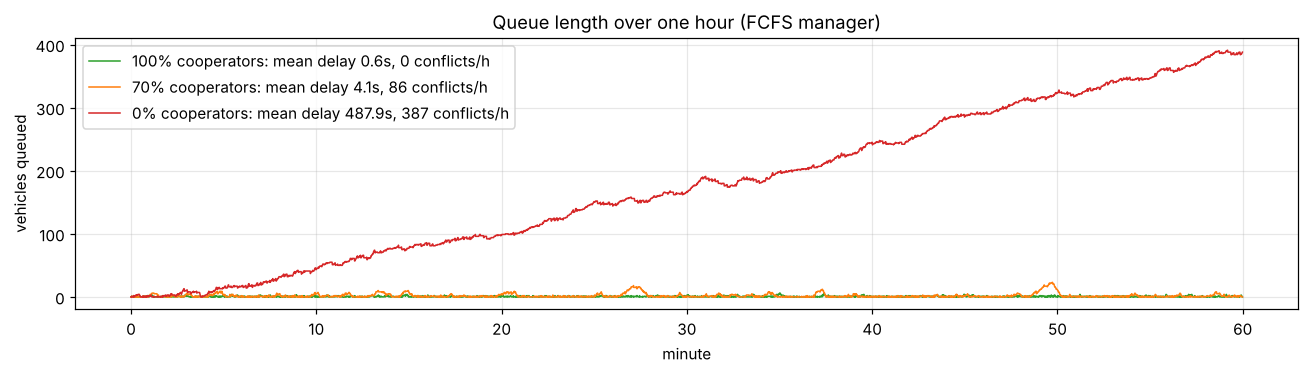

In [5]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for p, c in [(1.0, "tab:green"), (0.7, "tab:orange"), (0.0, "tab:red")]:
    rr = simulate(p, "fcfs", 1, record=True)
    ax.plot(np.arange(HORIZON) / 60, rr["queue_length"], c=c, lw=1,
            label=f"{p:.0%} cooperators: mean delay {rr['mean_delay']:.1f}s, {rr['conflicts_per_hour']:.0f} conflicts/h")
ax.set(xlabel="minute", ylabel="vehicles queued", title="Queue length over one hour (FCFS manager)"); ax.legend(); plt.tight_layout(); plt.show()

## 3. Experiment registry and the statistician

Experiments are fixed, named designs. The hypothesis agent may choose among them but cannot invent new code paths. Each experiment defines a **primary effect Δ**, and the hypothesis predicts its sign.

In [6]:
SEEDS = list(range(30))
LEVELS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

@lru_cache(maxsize=None)
def grid(protocol: str) -> pd.DataFrame:
    return pd.DataFrame([simulate(p, protocol, s) for p in LEVELS for s in SEEDS])

def boot_ci(x, n=4000, seed=0):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    rng = np.random.default_rng(seed)
    means = rng.choice(x, (n, len(x))).mean(1)
    return float(x.mean()), float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))

def stat_participation():
    g = grid("fcfs")
    by = {p: g[g.participation == p] for p in (0.0, 0.5, 1.0)}
    diff = by[1.0].set_index("seed").mean_delay - by[0.0].set_index("seed").mean_delay     # paired by seed
    facts = {}
    for p in (0.0, 0.5, 1.0):
        m, lo, hi = boot_ci(by[p].mean_delay)
        facts[f"delay_{int(p*100)}"] = (f"mean delay at {p:.0%} cooperators (s)", m, lo, hi)
        facts[f"conf_{int(p*100)}"] = (f"conflicts per hour at {p:.0%} cooperators", *boot_ci(by[p].conflicts_per_hour))
        facts[f"compl_{int(p*100)}"] = (f"completion at {p:.0%} cooperators (%)", *[100 * v for v in boot_ci(by[p].completion)])
    return facts, ("Δ = delay(100% cooperators) − delay(0% cooperators), seconds", *boot_ci(diff))

def stat_incentive():
    g = grid("fcfs"); g = g[g.participation == 0.5]
    diff = g.defector_delay - g.coop_delay
    facts = {"defector_delay_50": ("mean delay of defectors at 50% cooperators (s)", *boot_ci(g.defector_delay)),
             "coop_delay_50": ("mean delay of cooperators at 50% cooperators (s)", *boot_ci(g.coop_delay))}
    return facts, ("Δ = defector delay − cooperator delay at 50% cooperators, seconds", *boot_ci(diff))

def stat_protocol():
    f, a = grid("fcfs"), grid("auction")
    f, a = f[f.participation == 1.0].set_index("seed"), a[a.participation == 1.0].set_index("seed")
    facts = {"fcfs_vwd": ("value-weighted delay, FCFS, 100% cooperators (s)", *boot_ci(f.value_weighted_delay)),
             "auction_vwd": ("value-weighted delay, auction, 100% cooperators (s)", *boot_ci(a.value_weighted_delay)),
             "fcfs_delay": ("mean delay, FCFS, 100% cooperators (s)", *boot_ci(f.mean_delay)),
             "auction_delay": ("mean delay, auction, 100% cooperators (s)", *boot_ci(a.mean_delay))}
    return facts, ("Δ = auction − FCFS value-weighted delay at 100% cooperators, seconds", *boot_ci(a.value_weighted_delay - f.value_weighted_delay))

EXPERIMENTS = {
    "participation_sweep": {"desc": "FCFS manager; cooperator share 0%..100%; 30 seeds each. Primary Δ = delay(100%) − delay(0%).",
                            "answers": "how overall intersection delay, conflicts and completion change as the share of cooperating, protocol-following vehicles rises",
                            "sign": "negative = delay falls as cooperation rises; positive = delay rises", "fn": stat_participation},
    "individual_incentive": {"desc": "FCFS manager at 50% cooperators; compares defectors' and cooperators' delay. Primary Δ = defector − cooperator delay.",
                             "answers": "whether an individual vehicle gains by defecting and acting selfishly instead of cooperating",
                             "sign": "negative = defectors wait LESS (defecting pays individually); positive = defectors wait more", "fn": stat_incentive},
    "protocol_comparison": {"desc": "All cooperators; auction vs FCFS. Primary Δ = auction − FCFS value-weighted delay.",
                            "answers": "whether an auction coordination protocol beats first-come-first-served reservation",
                            "sign": "negative = the auction gives lower value-weighted delay; positive = FCFS is better", "fn": stat_protocol},
}

def verdict(predicted: str, lo: float, hi: float) -> bool:
    observed = "positive" if lo > 0 else "negative" if hi < 0 else "no_difference"
    return predicted == observed, observed

t0 = time.time()
for proto in ("fcfs", "auction"):
    grid(proto)
print(f"ran {2 * len(LEVELS) * len(SEEDS)} simulations in {time.time() - t0:.0f}s")

ran 660 simulations in 10s


## 4. Research agents

### 4.1 Hypothesis agent and analyst (LLM)

In [7]:
class Hypothesis(BaseModel):
    hypothesis: str
    experiment: str
    predicted_direction: Literal["positive", "negative", "no_difference"]

class Finding(BaseModel):
    finding: str
    hypothesis_supported: bool

def hypothesis_agent(question: str) -> Hypothesis:
    system = ("You are a transport-systems researcher. Given a research question, state ONE testable hypothesis, pick the experiment "
              "that tests it, and predict the sign of that experiment's primary effect Δ. Reply with JSON only: "
              '{"hypothesis": str, "experiment": str, "predicted_direction": "positive"|"negative"|"no_difference"}.\n'
              "Experiments:\n" + "\n".join(f"- {k}: answers {v['answers']}. {v['desc']} Sign of Δ: {v['sign']}." for k, v in EXPERIMENTS.items()))
    return llm.structured([{"role": "system", "content": system}, {"role": "user", "content": question}], Hypothesis, max_tokens=160)

def fmt(v):
    return f"{v:.2f}"

def facts_text(facts, effect):
    lines = [f"- {label}: {fmt(m)} (95% CI {fmt(lo)} to {fmt(hi)})" for label, m, lo, hi in facts.values()]
    lines.append(f"- PRIMARY {effect[0]}: {fmt(effect[1])} (95% CI {fmt(effect[2])} to {fmt(effect[3])})")
    return "\n".join(lines)

def analyst(question, hyp, facts, effect, feedback=None):
    system = ("You are a careful research analyst. Write a 2-3 sentence finding that answers the question, using ONLY the numbers listed "
              "(copy them exactly as written). State whether the hypothesis is supported: it is supported only if the primary Δ's "
              "confidence interval excludes zero in the predicted direction, or includes zero when 'no_difference' was predicted. "
              "The finding must be full sentences that state the primary Δ with its confidence interval and say what it means in plain words. "
              'Reply with JSON only: {"finding": str, "hypothesis_supported": true|false}. Example finding: '
              '"Mean delay fell from 12.30 s with no cooperators to 1.10 s with full cooperation (Δ = -11.20 s, 95% CI -12.00 to -10.40), so cooperation sharply reduces delay."')
    exp_ = EXPERIMENTS[hyp.experiment]
    user = (f"Question: {question}\nHypothesis: {hyp.hypothesis}\nPredicted direction of Δ: {hyp.predicted_direction} ({exp_['sign']})\nResults:\n{facts_text(facts, effect)}"
            + (f"\n\nYour previous draft was rejected by the reviewer: {feedback}\nFix these problems." if feedback else ""))
    return llm.structured([{"role": "system", "content": system}, {"role": "user", "content": user}], Finding, max_tokens=200)

### 4.2 Claim critic (deterministic)

A finding passes only if:

1. every number in it matches a statistician output at the precision it is written, or is a design parameter such as a participation level; and
2. its `hypothesis_supported` flag agrees with the confidence-interval test; and
3. it is written as sentences, reports the primary effect Δ, and any "rose/fell from A to B" matches the direction of the numbers.

In [8]:
NUM_RX = re.compile(r"(?<![\w.])[-−]?\d+(?:\.\d+)?")

DESIGN_NUMBERS = [0.0, 50.0, 100.0, 0.5, 1.0, 95.0, 30.0]   # participation levels, CI level, number of seeds

def allowed_numbers(facts, effect):
    vals = [x for _, *ms in facts.values() for x in ms] + list(effect[1:])
    return vals + [abs(v) for v in vals]

def grounded(tok: str, allowed) -> bool:
    """A quoted number is grounded if some statistic rounds to it at the precision it was written (0, 1 or 2 decimals)."""
    v = float(tok.replace("−", "-"))
    d = min(2, len(tok.split(".")[1])) if "." in tok else 0
    if any(abs(v - x) < 1e-9 for x in DESIGN_NUMBERS):
        return True
    return any(round(x, d) == round(abs(v), d) or round(x, d) == round(v, d) for x in allowed if d > 0 or abs(x) >= 10)

def claim_critic(finding: Finding, facts, effect, predicted):
    problems = []
    allowed = allowed_numbers(facts, effect)
    for tok in NUM_RX.findall(finding.finding):
        if not grounded(tok, allowed):
            problems.append(f"number {tok} does not appear in the results")
    ok, observed = verdict(predicted, effect[2], effect[3])
    if finding.hypothesis_supported != ok:
        problems.append(f"hypothesis_supported must be {str(ok).lower()}: predicted {predicted}, but the CI ({fmt(effect[2])} to {fmt(effect[3])}) indicates {observed}")
    if not NUM_RX.search(finding.finding):
        problems.append("the finding must quote at least one result")
    # direction words must match the numbers: "rose from 9.1 to 0.6" is wrong even if both numbers are right
    for m in re.finditer(r"\b(increased|rose|grew|climbed|fell|decreased|dropped|declined)\s+(?:\w+\s+){0,3}?from\s+([-−]?\d+(?:\.\d+)?)"
                         r"[^.]*?\bto\s+([-−]?\d+(?:\.\d+)?)", finding.finding, re.I):
        up = m.group(1).lower() in ("increased", "rose", "grew", "climbed")
        a_, b_ = float(m.group(2).replace("−", "-")), float(m.group(3).replace("−", "-"))
        if (b_ > a_) != up and a_ != b_:
            problems.append(f"'{m.group(1)} from {m.group(2)} to {m.group(3)}' states the wrong direction")
    if len(re.findall(r"[A-Za-z]{3,}", finding.finding)) < 12:
        problems.append("the finding must be one to three full sentences explaining the result in words, not just numbers")
    if not any(grounded(tok, [effect[1], abs(effect[1])]) and abs(float(tok.replace("−", "-"))) > 0 for tok in NUM_RX.findall(finding.finding)) and abs(effect[1]) >= 0.005:
        problems.append(f"the finding must state the primary Δ ({fmt(effect[1])}) and its confidence interval")
    return problems

### 4.3 LangGraph research loop

2026-11-24 16:15:02,040 WARNING huggingface_hub.utils._http | Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


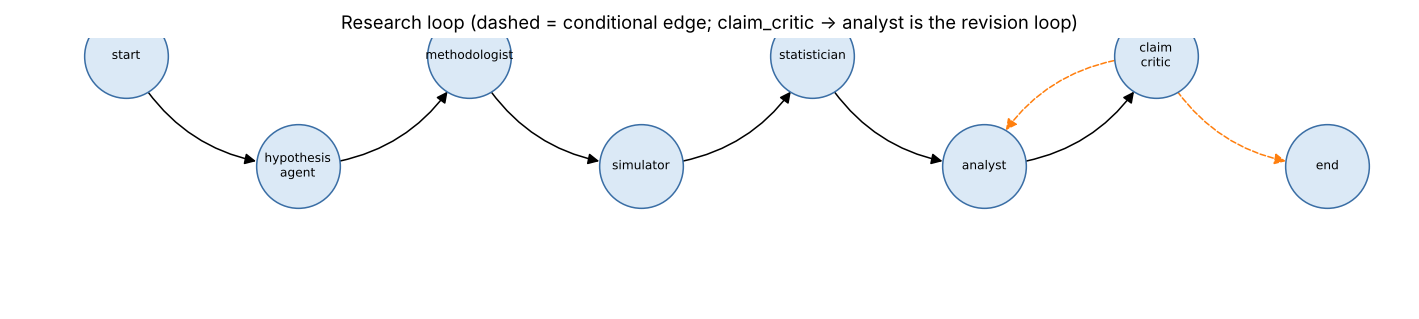

In [9]:
class LabState(TypedDict, total=False):
    qid: str
    question: str
    default_experiment: str
    hyp: Hypothesis
    hyp_overridden: bool
    facts: dict
    effect: tuple
    finding: Finding
    problems: list
    attempts: int
    fallback: bool
    trace: list

MAX_REVISIONS = 2

def hypothesis_node(s):
    try:
        h = hypothesis_agent(s["question"])
    except RuntimeError as e:
        log.warning("hypothesis agent failed: %s", e)
        h = Hypothesis(hypothesis="(agent failed; default experiment used)", experiment=s["default_experiment"], predicted_direction="no_difference")
    overridden = h.experiment not in EXPERIMENTS
    if overridden:
        h = h.model_copy(update={"experiment": s["default_experiment"]})
    return {"hyp": h, "hyp_overridden": overridden, "attempts": 0, "fallback": False,
            "trace": s["trace"] + [("hypothesis_agent", f"{h.hypothesis[:140]} | experiment={h.experiment}{' (overridden)' if overridden else ''} | predicts Δ {h.predicted_direction}")]}

# Methodologist: an independent check that the chosen experiment actually addresses the question.
# Questions and experiment descriptions are embedded with all-MiniLM-L6-v2. If the LLM's choice is clearly
# less relevant than the best match, the methodologist overrides it, and the override is recorded.
from sentence_transformers import SentenceTransformer
_embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
_exp_names = list(EXPERIMENTS)
_exp_vecs = _embedder.encode([EXPERIMENTS[k]["answers"] for k in _exp_names], normalize_embeddings=True)
OVERRIDE_MARGIN = 0.05

def methodologist_node(s):
    qv = _embedder.encode([s["question"]], normalize_embeddings=True)[0]
    sims = {k: round(float(v), 3) for k, v in zip(_exp_names, _exp_vecs @ qv)}
    best = max(sims, key=sims.get)
    chosen = s["hyp"].experiment
    if chosen != best and sims[best] - sims[chosen] > OVERRIDE_MARGIN:
        return {"hyp": s["hyp"].model_copy(update={"experiment": best}), "hyp_overridden": True,
                "trace": s["trace"] + [("methodologist", f"OVERRIDE {chosen} -> {best} (relevance {sims[chosen]} vs {sims[best]})")]}
    return {"trace": s["trace"] + [("methodologist", f"approved {chosen} (relevance {sims[chosen]}; best {best} {sims[best]})")]}

def simulator_node(s):
    proto = ["fcfs", "auction"] if s["hyp"].experiment == "protocol_comparison" else ["fcfs"]
    for p in proto:
        grid(p)                       # cached: each design is simulated once
    return {"trace": s["trace"] + [("simulator", f"{len(LEVELS) * len(SEEDS) * len(proto)} runs available for {proto}")]}

def statistician_node(s):
    facts, effect = EXPERIMENTS[s["hyp"].experiment]["fn"]()
    return {"facts": facts, "effect": effect,
            "trace": s["trace"] + [("statistician", f"{effect[0]}: {fmt(effect[1])} [{fmt(effect[2])}, {fmt(effect[3])}]")]}

def analyst_node(s):
    fb = "; ".join(s.get("problems") or []) or None
    try:
        f = analyst(s["question"], s["hyp"], s["facts"], s["effect"], fb)
    except RuntimeError as e:
        f = Finding(finding=f"(analyst failed: {e})", hypothesis_supported=False)
    return {"finding": f, "attempts": s["attempts"] + 1,
            "trace": s["trace"] + [("analyst", f"draft {s['attempts'] + 1}: {f.finding[:160]}")]}

def critic_node(s):
    probs = claim_critic(s["finding"], s["facts"], s["effect"], s["hyp"].predicted_direction)
    upd = {"problems": probs, "trace": s["trace"] + [("claim_critic", "PASS" if not probs else "REJECT: " + "; ".join(probs)[:200])]}
    if probs and s["attempts"] > MAX_REVISIONS:          # out of revisions: publish a template finding instead, and say so
        ok, observed = verdict(s["hyp"].predicted_direction, s["effect"][2], s["effect"][3])
        e = s["effect"]
        upd["finding"] = Finding(finding=f"{e[0]}: {fmt(e[1])} (95% CI {fmt(e[2])} to {fmt(e[3])}), i.e. {observed.replace('_', ' ')}. "
                                         f"The hypothesis (predicted {s['hyp'].predicted_direction}) is {'supported' if ok else 'not supported'}.",
                                 hypothesis_supported=ok)
        upd["fallback"] = True
        upd["trace"] = upd["trace"] + [("claim_critic", "revision budget exhausted: template finding used")]
    return upd

def route(s):
    return "revise" if s["problems"] and not s["fallback"] else "done"

g = StateGraph(LabState)
for n, fn in [("hypothesis_agent", hypothesis_node), ("methodologist", methodologist_node), ("simulator", simulator_node), ("statistician", statistician_node),
              ("analyst", analyst_node), ("claim_critic", critic_node)]:
    g.add_node(n, fn)
g.set_entry_point("hypothesis_agent")
g.add_edge("hypothesis_agent", "methodologist"); g.add_edge("methodologist", "simulator"); g.add_edge("simulator", "statistician"); g.add_edge("statistician", "analyst")
g.add_edge("analyst", "claim_critic")
g.add_conditional_edges("claim_critic", route, {"revise": "analyst", "done": END})
lab = g.compile()

G = lab.get_graph()
nxg = nx.DiGraph([(e.source, e.target, {"c": e.conditional}) for e in G.edges])
pos = {n: (i, 0.2 * (-1) ** i) for i, n in enumerate(["__start__", "hypothesis_agent", "methodologist", "simulator", "statistician", "analyst", "claim_critic", "__end__"])}
fig, ax = plt.subplots(figsize=(13, 3))
nx.draw_networkx_nodes(nxg, pos, node_color="#dbe9f6", node_size=3000, edgecolors="#3a6ea5", ax=ax)
nx.draw_networkx_labels(nxg, pos, labels={n: n.replace("_", "\n") for n in nxg}, font_size=8, ax=ax)
for c, st, col in [(False, "solid", "k"), (True, "dashed", "tab:orange")]:
    nx.draw_networkx_edges(nxg, pos, edgelist=[(u, v) for u, v, d in nxg.edges(data=True) if d["c"] == c], style=st, edge_color=col,
                           arrows=True, arrowsize=15, node_size=3000, connectionstyle="arc3,rad=0.3", ax=ax)
ax.set_title("Research loop (dashed = conditional edge; claim_critic → analyst is the revision loop)"); ax.axis("off"); plt.tight_layout(); plt.show()

## 5. Run the research agenda

In [10]:
QUESTIONS = [
    ("Q1", "How does average intersection delay change as the share of vehicles that follow the coordination protocol rises from 0% to 100%?", "participation_sweep"),
    ("Q2", "When half the vehicles cooperate, is it individually advantageous for a vehicle to defect and act selfishly?", "individual_incentive"),
    ("Q3", "With full cooperation, does an auction protocol reduce value-weighted delay compared with first-come-first-served reservation?", "protocol_comparison"),
]
outcomes = []
for qid, q, default in QUESTIONS:
    st = lab.invoke({"qid": qid, "question": q, "default_experiment": default, "trace": []})
    print(f"\n=== {qid}: {q}")
    for step, detail in st["trace"]:
        print(f"  [{step}] {detail}")
    display(Markdown(f"**Finding.** {st['finding'].finding}"))
    ok, observed = verdict(st["hyp"].predicted_direction, st["effect"][2], st["effect"][3])
    outcomes.append({"question": qid, "experiment": st["hyp"].experiment, "experiment kept (not overridden)": not st["hyp_overridden"],
                     "predicted Δ": st["hyp"].predicted_direction, "Δ": round(st["effect"][1], 2),
                     "95% CI": f"[{st['effect'][2]:.2f}, {st['effect'][3]:.2f}]", "observed": observed, "supported": ok,
                     "analyst drafts": st["attempts"], "critic passed": not st["fallback"]})
pd.DataFrame(outcomes).set_index("question")


=== Q1: How does average intersection delay change as the share of vehicles that follow the coordination protocol rises from 0% to 100%?
  [hypothesis_agent] As the share of vehicles that follow the coordination protocol rises, average intersection delay decreases. | experiment=participation_sweep | predicts Δ negative
  [methodologist] approved participation_sweep (relevance 0.789; best participation_sweep 0.789)
  [simulator] 330 runs available for ['fcfs']
  [statistician] Δ = delay(100% cooperators) − delay(0% cooperators), seconds: -503.26 [-526.83, -481.46]
  [analyst] draft 1: Mean delay increased from 503.85 s with 0% cooperators to 0.60 s with 100% cooperators (Δ = -503.26 s, 95% CI -526.83 to -481.46), so cooperation sharply reduce
  [claim_critic] REJECT: 'increased from 503.85 to 0.60' states the wrong direction
  [analyst] draft 2: Mean delay increased from 503.85 s with 0% cooperators to 0.60 s with 100% cooperators (Δ = -503.26 s, 95% CI -526.83 to -481.46), so cooperat

**Finding.** Δ = delay(100% cooperators) − delay(0% cooperators), seconds: -503.26 (95% CI -526.83 to -481.46), i.e. negative. The hypothesis (predicted negative) is supported.


=== Q2: When half the vehicles cooperate, is it individually advantageous for a vehicle to defect and act selfishly?
  [hypothesis_agent] When half the vehicles cooperate, it is individually advantageous for a vehicle to defect and act selfishly. | experiment=individual_incentive | predicts Δ positive
  [methodologist] approved individual_incentive (relevance 0.868; best individual_incentive 0.868)
  [simulator] 330 runs available for ['fcfs']
  [statistician] Δ = defector delay − cooperator delay at 50% cooperators, seconds: -1.53 [-1.74, -1.32]
  [analyst] draft 1: Mean delay of defectors at 50% cooperators was 8.30 s (95% CI 7.37 to 9.43), and mean delay of cooperators was 9.82 s (95% CI 8.87 to 10.91). The PRIMARY Δ = de
  [claim_critic] REJECT: hypothesis_supported must be false: predicted positive, but the CI (-1.74 to -1.32) indicates negative
  [analyst] draft 2: Mean delay of defectors at 50% cooperators was 8.30 s (95% CI 7.37 to 9.43), and mean delay of cooperators was 9.82

**Finding.** Mean delay of defectors at 50% cooperators was 8.30 s (95% CI 7.37 to 9.43), and mean delay of cooperators was 9.82 s (95% CI 8.87 to 10.91). The PRIMARY Δ = defector delay − cooperator delay at 50% cooperators was -1.53 s (95% CI -1.74 to -1.32), indicating that defectors wait less than cooperators (defecting pays individually).


=== Q3: With full cooperation, does an auction protocol reduce value-weighted delay compared with first-come-first-served reservation?
  [hypothesis_agent] An auction protocol reduces value-weighted delay compared with first-come-first-served reservation when there is full cooperation. | experiment=protocol_comparison | predicts Δ negative
  [methodologist] approved protocol_comparison (relevance 0.821; best protocol_comparison 0.821)
  [simulator] 660 runs available for ['fcfs', 'auction']
  [statistician] Δ = auction − FCFS value-weighted delay at 100% cooperators, seconds: -0.11 [-0.12, -0.10]
  [analyst] draft 1: Value-weighted delay fell from 0.60 s with FCFS to 0.49 s with auction (Δ = -0.11 s, 95% CI -0.12 to -0.10), so auction reduces delay compared with FCFS when th
  [claim_critic] PASS


**Finding.** Value-weighted delay fell from 0.60 s with FCFS to 0.49 s with auction (Δ = -0.11 s, 95% CI -0.12 to -0.10), so auction reduces delay compared with FCFS when there is full cooperation.

,experiment,experiment kept (not overridden),predicted Δ,Δ,95% CI,observed,supported,analyst drafts,critic passed
question,,,,,,,,,
Q1,participation_sweep,True,negative,-503.26,"[-526.83, -481.46]",negative,True,3,False
Q2,individual_incentive,True,positive,-1.53,"[-1.74, -1.32]",negative,False,2,True
Q3,protocol_comparison,True,negative,-0.11,"[-0.12, -0.10]",negative,True,1,True


## 6. Full results

The research loop reports three headline effects. The full sweep is shown below: mean delay, conflicts and completion against the cooperator share, with 95% bootstrap bands over 30 seeds.

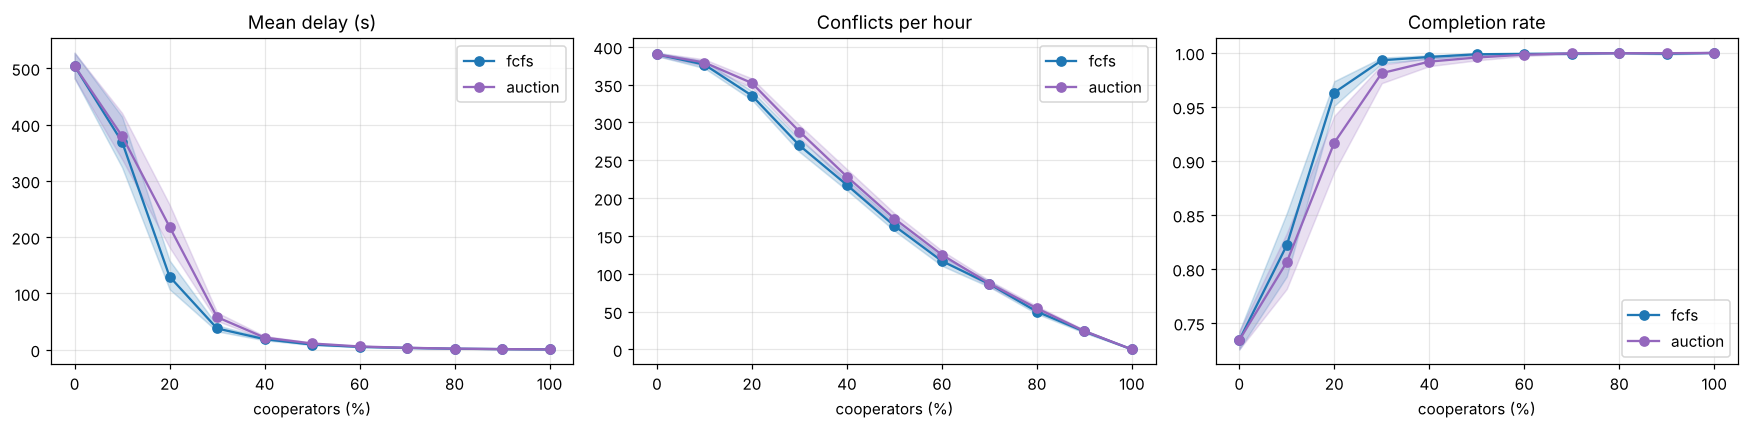

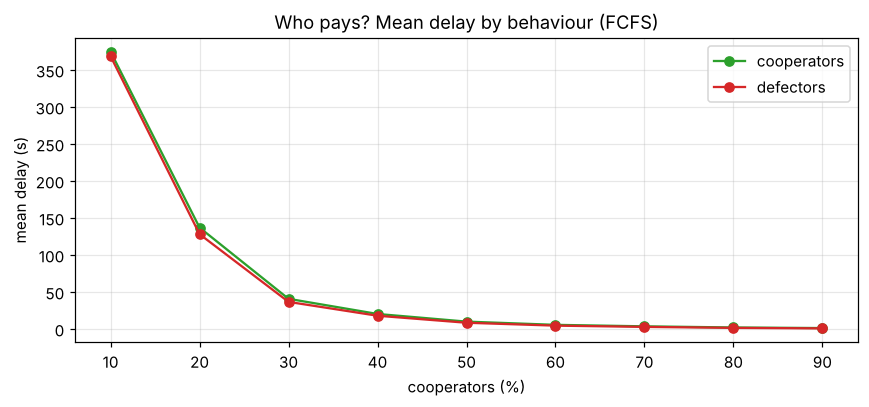

wrote outputs/participation_sweep.html and outputs/simulation_results.csv


In [11]:
def summarise(col):
    rows = []
    for proto in ("fcfs", "auction"):
        g = grid(proto)
        for p in LEVELS:
            m, lo, hi = boot_ci(g[g.participation == p][col])
            rows.append({"protocol": proto, "participation": p, "mean": m, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, title) in zip(axes, [("mean_delay", "Mean delay (s)"), ("conflicts_per_hour", "Conflicts per hour"), ("completion", "Completion rate")]):
    sm = summarise(col)
    for proto, c in [("fcfs", "tab:blue"), ("auction", "tab:purple")]:
        d = sm[sm.protocol == proto]
        ax.plot(d.participation * 100, d["mean"], marker="o", c=c, label=proto)
        ax.fill_between(d.participation * 100, d.lo, d.hi, color=c, alpha=0.2)
    ax.set(title=title, xlabel="cooperators (%)"); ax.legend()
plt.tight_layout(); plt.show()

g = grid("fcfs")
inc = g[(g.participation > 0) & (g.participation < 1)].groupby("participation")[["coop_delay", "defector_delay"]].agg(lambda x: boot_ci(x)[0])
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(inc.index * 100, inc.coop_delay, marker="o", c="tab:green", label="cooperators")
ax.plot(inc.index * 100, inc.defector_delay, marker="o", c="tab:red", label="defectors")
ax.set(title="Who pays? Mean delay by behaviour (FCFS)", xlabel="cooperators (%)", ylabel="mean delay (s)"); ax.legend(); plt.tight_layout(); plt.show()

sm = summarise("mean_delay")
fig = go.Figure()
for proto in ("fcfs", "auction"):
    d = sm[sm.protocol == proto]
    fig.add_trace(go.Scatter(x=d.participation * 100, y=d["mean"], name=proto, error_y=dict(type="data", symmetric=False, array=d.hi - d["mean"], arrayminus=d["mean"] - d.lo)))
fig.update_layout(title="Mean delay vs cooperator share (interactive)", xaxis_title="cooperators (%)", yaxis_title="seconds")
fig.write_html(OUT / "participation_sweep.html", include_plotlyjs="cdn")
grid("fcfs").assign(protocol="fcfs").pipe(lambda d: pd.concat([d, grid("auction")])).to_csv(OUT / "simulation_results.csv", index=False)
print("wrote outputs/participation_sweep.html and outputs/simulation_results.csv")

## 7. Discussion

* **The commons dilemma.** Compare the participation sweep with the "who pays" chart. If defectors experience less delay than cooperators at the same participation level, while total delay rises as defection spreads, the setting has the structure of a social dilemma: defecting is individually tempting and collectively costly. The research loop tests each part separately, and the tables above report what the simulation actually showed, including any hypothesis that was not supported.
* **Protocol design.** The auction ranks vehicles by value of time, which targets value-weighted delay rather than plain average delay; Q3 measures whether that pays off under this demand level.
* **Agentic research loop.** The LLM only proposes hypotheses and writes prose. Simulation and statistics are deterministic code. The claim critic blocks any number the statistician did not produce, and any verdict that contradicts the confidence interval. When the analyst cannot produce a compliant finding within the revision budget, a template finding is published and flagged in the outcomes table.

**Limitations.** This is a stylised single intersection with no turning movements, vehicle dynamics or learning, and a fixed defection rule. Results depend on the demand level `LAM`, the conflict penalty and `P_ERR`, so treat them as illustrations of the mechanisms, not calibrated traffic predictions. Natural extensions include agents that *learn* whether to defect (evolutionary or reinforcement-learning dynamics), road networks, and payments in the auction to study incentive compatibility.

In [12]:
llm.report()

LLM provenance for this run
  huggingface/Qwen/Qwen3-1.7B: no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory
  LIVE  huggingface/Qwen/Qwen3-1.7B: 9 calls, 4329 in / 738 out tokens, 154s, $0 (local)
  live calls: 9 | replayed from cache: 0 | retries: 0 | fallbacks: 0


{'provider': 'huggingface',
 'model': 'Qwen/Qwen3-1.7B',
 'revision': None,
 'selection': 'no API key and no Ollama server: running offline with a local Hugging Face model; best Apache-2.0 model that fits 7.4 GB free cpu memory',
 'cache_mode': 'off',
 'stats': {'calls': 9,
  'live_calls': 9,
  'cache_hits': 0,
  'seconds': 153.98043727874756,
  'input_tokens': 4329,
  'output_tokens': 738,
  'retries': 0,
  'fallbacks': 0,
  'errors': 0},
 'events': [],
 'python': '3.13.18',
 'by_source': [{'provider': 'huggingface',
   'model': 'Qwen/Qwen3-1.7B',
   'source': 'live',
   'calls': 9,
   'input_tokens': 4329,
   'output_tokens': 738,
   'seconds': 153.97899999999998,
   'est_cost_usd': 0.0,
   'errors': 0}]}